In [1]:
print('Hello World')

Hello World


### The four building blocks
#### 1. State is the shared data that moves through the graph. You define it as a TypedDict. Every node reads from it and adds to it.

In [ ]:
from typing import TypedDict
from typing_extensions import NotRequired

class BMIState(TypedDict):
    weight_kg: float              # required input
    height_m: float               # required input
    bmi: NotRequired[float]       # set by calculate_bmi
    category: NotRequired[str]    # set by classify
    error: NotRequired[str]       # set by validate



##### Nodes

In [5]:
def calculate_bmi(state: BMIState) -> dict:
    bmi = state["weight_kg"] / (state["height_m"] ** 2)
    return {"bmi": round(bmi, 2)}


In [6]:
def validate(state: BMIState) -> dict:
    if state["weight_kg"] <= 0 or state["height_m"] <= 0:
        return {"error": "Weight and height must be positive numbers."}
    return {}

In [7]:
def classify(state: BMIState) -> dict:
    bmi = state["bmi"]  # type: ignore
    if bmi < 18.5:
        category = "Underweight"
    elif bmi < 25:
        category = "Normal weight"
    elif bmi < 30:
        category = "Overweight"
    else:
        category = "Obese"
    return {"category": category}

In [8]:
def handle_error(state: BMIState) -> dict:
    return {"category": "Unknown"}

##### Router

In [9]:
def route_after_validate(state: BMIState) -> str:
    return "invalid" if state.get("error") else "valid"

##### 4. BUILD THE GRAPH: register nodes, then connect them with edges.

In [25]:

from langgraph.graph import StateGraph, END, START

builder = StateGraph(BMIState)
builder.add_node("calculate_bmi", calculate_bmi)
builder.add_node("validate", validate)
builder.add_node("classify", classify)
builder.add_node("handle_error", handle_error)


builder.add_edge(START, "validate")
builder.add_conditional_edges("validate", route_after_validate, 
                              {"valid": "calculate_bmi", "invalid": "handle_error"})
builder.add_edge("calculate_bmi", "classify")
builder.add_edge("classify", END)
builder.add_edge("handle_error", END)
graph = builder.compile()

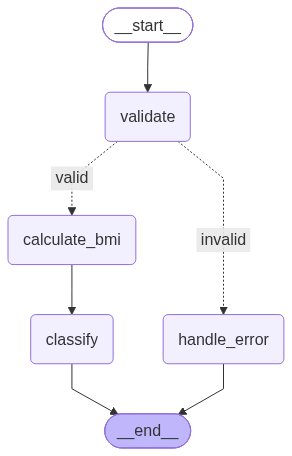

In [27]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
initial_state: BMIState = {"weight_kg": 78, "height_m": 1.75} 
print(graph.invoke(initial_state))
# print(graph.invoke({"weight_kg": 95, "height_m": 1.70}))
# print(graph.invoke({"weight_kg": -5, "height_m": 1.70}))

# Watch each node's update as it happens
for step in graph.stream({"weight_kg": 50, "height_m": 1.80}):
    print("step:", step)

# Print the graph structure as a Mermaid diagram
# print(graph.get_graph().draw_mermaid())

{'weight_kg': 78, 'height_m': 1.75, 'bmi': 25.47, 'category': 'Overweight'}
step: {'validate': None}
step: {'calculate_bmi': {'bmi': 15.43}}
step: {'classify': {'category': 'Underweight'}}
